# 第6章：概率、损失与阈值

**学生实验｜全书深化稿**

## 背景与数据
Wine为真实标准分类数据；八条概率—标签记录是为了完整统计阈值效果的人工表。

## 本次要回答的问题
手算一次逻辑回归更新，逐阈值统计TP/FP/FN/TN，再做Wine统一验证。

先写下预判，再运行，最后用实际结果解释；不需要结果符合预期才算成功。

In [1]:
from pathlib import Path
import os, sys
os.environ.setdefault("OMP_NUM_THREADS", "1")
os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")
os.environ.setdefault("MKL_NUM_THREADS", "1")
root = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "experiments/common.py").exists()
             and (p / "main.tex").exists()), None)
if root is None:
    raise RuntimeError("Open this notebook inside the extracted textbook project.")
sys.path.insert(0, str(root / "experiments"))
print("Project:", root)


Project: /mnt/data/book_v3


## 可检查的完整实验代码

下方与对应`experiments`脚本一致。共享的`common.py`只提供固定数据划分、保存表图和绘图设置；模型、目标、参数及比较规则在此明确写出。阅读函数后，再运行下一单元执行实验。

In [2]:
"""Chapter 6: probability, gradient and thresholds with actual boundary cases."""
import numpy as np
from scipy.special import expit
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import cross_validate
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import confusion_matrix,precision_score,recall_score,log_loss,brier_score_loss
from common import *

def run():
    # Fixed artificial probabilities, not claimed to be fitted model predictions.
    p=np.array([.95,.80,.60,.55,.40,.30,.10,.05]);y=np.array([1,1,0,1,0,1,0,0])
    rows=[]
    for t in [.2,.5,.8]:
        pred=p>=t;tn,fp,fn,tp=confusion_matrix(y,pred,labels=[0,1]).ravel()
        rows.append({'threshold':t,'TP':tp,'FP':fp,'FN':fn,'TN':tn,
        'precision':precision_score(y,pred,zero_division=0),'recall':recall_score(y,pred,zero_division=0)})
    df=table('ch06_threshold_hand',rows);show_result(df)
    # One simultaneous gradient update, mean binary cross entropy.
    x=np.array([-1.,0.,1.]);target=np.array([0.,0.,1.]);w=0.;b=0.
    prob=expit(w*x+b);dw=np.mean((prob-target)*x);db=np.mean(prob-target)
    wn=w-.3*dw;bn=b-.3*db
    before=log_loss(target,prob);after=log_loss(target,expit(wn*x+bn))
    assert after<before
    dump('ch06_gradient',{'dw':dw,'db':db,'w_new':wn,'b_new':bn,'loss_before':before,'loss_after':after})
    X,y,_=development('wine');splits=list(cv5().split(X,y));rows=[]
    for name,m in [('logistic_C0.1',make_pipeline(StandardScaler(),LogisticRegression(C=.1,max_iter=3000))),
       ('logistic_C1',make_pipeline(StandardScaler(),LogisticRegression(C=1,max_iter=3000))),
       ('GaussianNB',GaussianNB())]:
        r=cross_validate(m,X,y,cv=splits,scoring=['accuracy','neg_log_loss'])
        rows.append({'model':name,'accuracy_mean':r['test_accuracy'].mean(),'accuracy_std':r['test_accuracy'].std(),
        'log_loss_mean':-r['test_neg_log_loss'].mean()})
    df=table('ch06_wine_models',rows);show_result(df)
    plt.figure(figsize=(6.4,4));plt.plot(np.arange(len(p)),p,'o',label='prescribed probability')
    for t in [.2,.5,.8]:plt.axhline(t,linestyle='--',label=f'threshold={t}')
    plt.xticks(np.arange(len(p)),[f'{i+1}\ny={v}' for i,v in enumerate(y[:0])]) if False else None
    plt.xlabel('人工样本编号（从0开始）');plt.ylabel('正类概率');plt.legend();figure('v3_ch06_thresholds')

In [3]:
result = run()
if result is not None:
    print(result)

 threshold  TP  FP  FN  TN  precision  recall
       0.2   4   2   0   2   0.666667    1.00
       0.5   3   1   1   3   0.750000    0.75
       0.8   2   0   2   4   1.000000    0.50


        model  accuracy_mean  accuracy_std  log_loss_mean
logistic_C0.1       0.985961      0.017199       0.162739
  logistic_C1       0.978818      0.017301       0.073231
   GaussianNB       0.965025      0.021817       0.090288


## 检查结果文件与图

下面显示该实验保存的图；所有坐标、样本与数值条件应与正文一致。数据表保存在`results/`。修改代码后，请另存结果或注明变化，不把新配置的输出与正文旧数值混用。

v3_ch06_thresholds.png


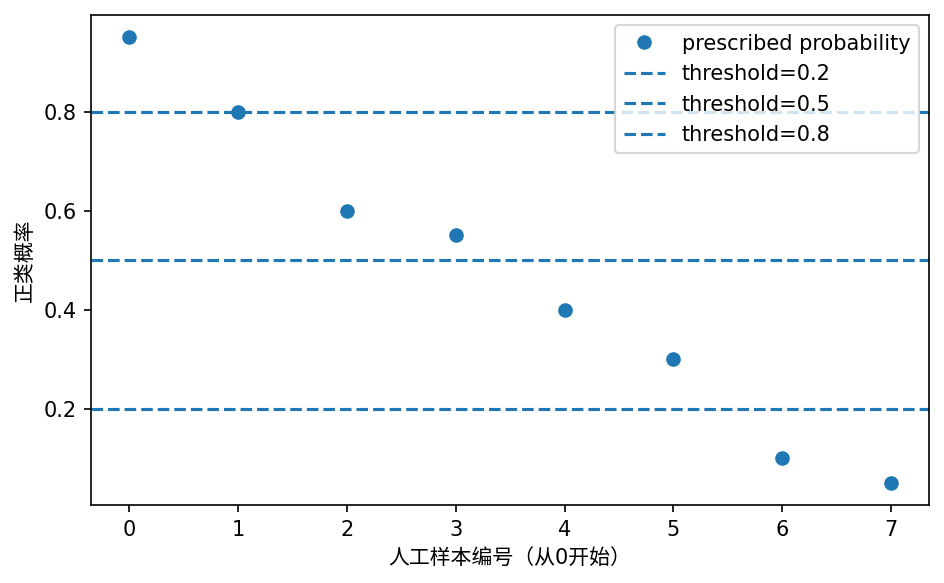

In [4]:
from IPython.display import display, Image
files = sorted((root / "figures").glob("v3_ch06_*.png"))
for path in files:
    print(path.name)
    display(Image(filename=str(path), width=720))
if not files:
    print("This experiment uses tables rather than a new figure.")

## 运行后的分析

解释一个与你的预判一致的结果，再解释一个需要进一步检查的现象。指出训练、验证和测试各使用哪些记录。

手算一次逻辑回归更新，逐阈值统计TP/FP/FN/TN，再做Wine统一验证。

**提交要求：**保存可顺序运行的Notebook、一个关键结果表、必要图形，以及150—300字的机制与限制解释。完成正文D题中与本实验相关的计算。不得仅提交最高分截图。